# LAB 10: Comparative Implementation of Machine Learning Regression Algorithms

**Course:** Machine Learning / Computer Vision  
**Author:** Atif Ali Shah  
**Student ID:** FA23-BAI-004  
**Degree:** BS Artificial Intelligence  
**Institution:** Department of Computer Science / Artificial Intelligence  

---

## 1. Assignment Overview and Objectives
In this laboratory assignment, we conduct a rigorous comparative study across **six foundational and modern machine learning regression algorithms**:
1. **Ordinary Least Squares Linear Regression**
2. **Decision Tree Regression (CART)**
3. **Random Forest Regression (Ensemble Bagging)**
4. **Multilayer Perceptron Neural Network Regression (MLPRegressor)**
5. **XGBoost Regression (Extreme Gradient Boosting)**
6. **K-Nearest Neighbors Regression (Distance-Weighted KNN)**

### Prediction Objective
Every algorithm is evaluated on the exact same task: predicting the **continuous median house value (`MedHouseVal`)** of California districts using socioeconomic, geographic, and housing density indicators. All models are trained and tested on an identical 80:20 split (`random_state=42`) with standardized evaluation metrics (**MAE, MSE, RMSE, R² Score**).

## 2. Dataset Description: California Housing
We employ the **California Housing Dataset**, derived from the 1990 U.S. Census in California. It contains **20,640 census block groups** with 8 input feature variables and 1 target variable:

| Feature | Type | Unit | Description |
|:---|:---:|:---:|:---|
| `MedInc` | Continuous | $10,000s | Median income in block group |
| `HouseAge` | Continuous | Years | Median house age in block group |
| `AveRooms` | Continuous | Ratio | Average number of rooms per household |
| `AveBedrms` | Continuous | Ratio | Average number of bedrooms per household |
| `Population` | Continuous | Persons | Block group population count |
| `AveOccup` | Continuous | Ratio | Average number of household members |
| `Latitude` | Continuous | Degrees | Block group latitude coordinate |
| `Longitude` | Continuous | Degrees | Block group longitude coordinate |
| **`MedHouseVal` (Target)** | Continuous | $100,000s | Median house value for California districts |

In [1]:
# 3. Library Imports
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn modules
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Regression Models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
import xgboost as xgb

# Set plotting styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10.5
plt.rcParams['figure.titlesize'] = 13
%matplotlib inline

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [2]:
# 4. Dataset Loading
housing_data = fetch_california_housing(as_frame=True)
df = housing_data.frame.copy()

print(f"Dataset Shape: {df.shape[0]} samples, {df.shape[1]} attributes")
df.head(5)

Dataset Shape: 20640 samples, 9 attributes


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
# 5. Initial Dataset Inspection
print("--- Column Data Types & Non-Null Values ---")
df.info()

print("\n--- Missing Values Check ---")
print(df.isnull().sum())

print(f"\nTotal duplicate rows: {df.duplicated().sum()}")

--- Column Data Types & Non-Null Values ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

--- Missing Values Check ---
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Total duplicate rows: 0


## 6. Exploratory Data Analysis (EDA)
Let us compute descriptive statistics, inspect the target variable distribution, and compute Pearson correlation coefficients across all features.

In [4]:
# Descriptive Statistics
df.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


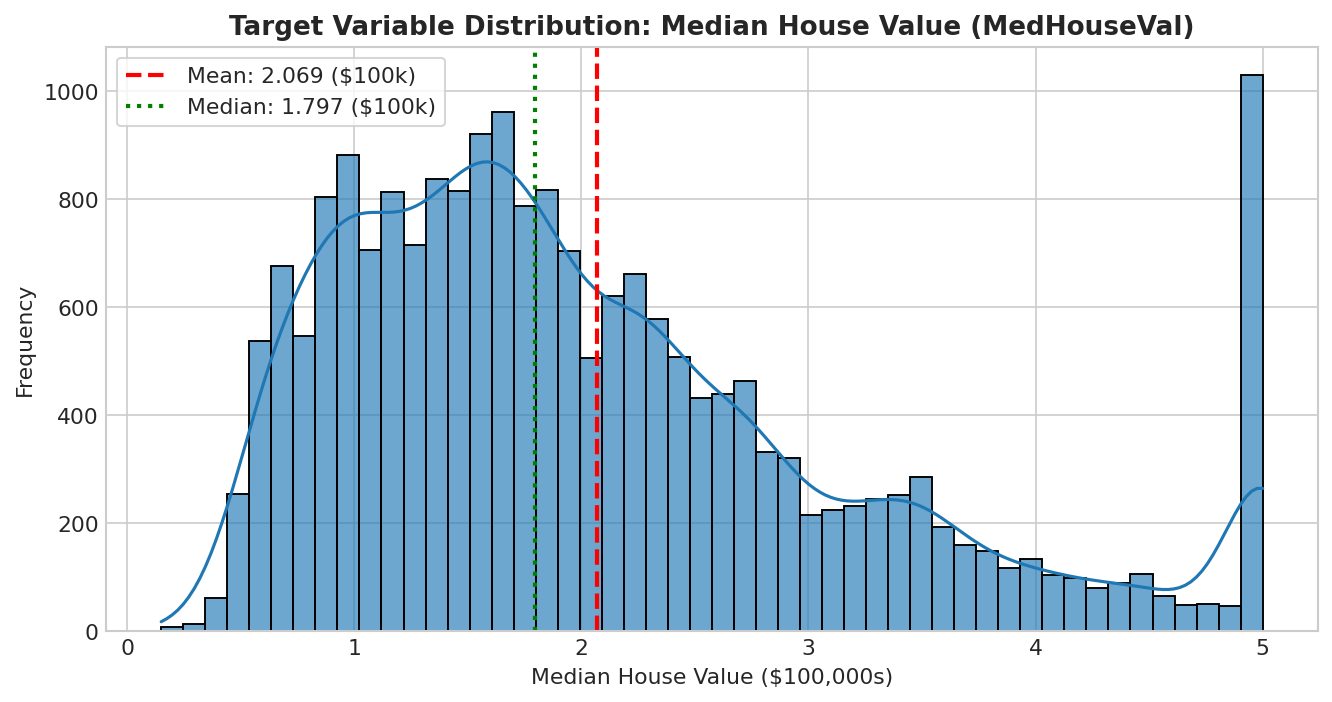

In [5]:
# Target Variable Distribution
plt.figure(figsize=(9, 4.8), dpi=150)
sns.histplot(df['MedHouseVal'], kde=True, bins=50, color='#1f77b4', edgecolor='black', alpha=0.65)
mean_val = df['MedHouseVal'].mean()
median_val = df['MedHouseVal'].median()

plt.axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_val:.3f} ($100k)')
plt.axvline(median_val, color='green', linestyle=':', linewidth=2, label=f'Median: {median_val:.3f} ($100k)')
plt.title('Target Variable Distribution: Median House Value (MedHouseVal)', fontweight='bold')
plt.xlabel('Median House Value ($100,000s)')
plt.ylabel('Frequency')
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()
plt.show()

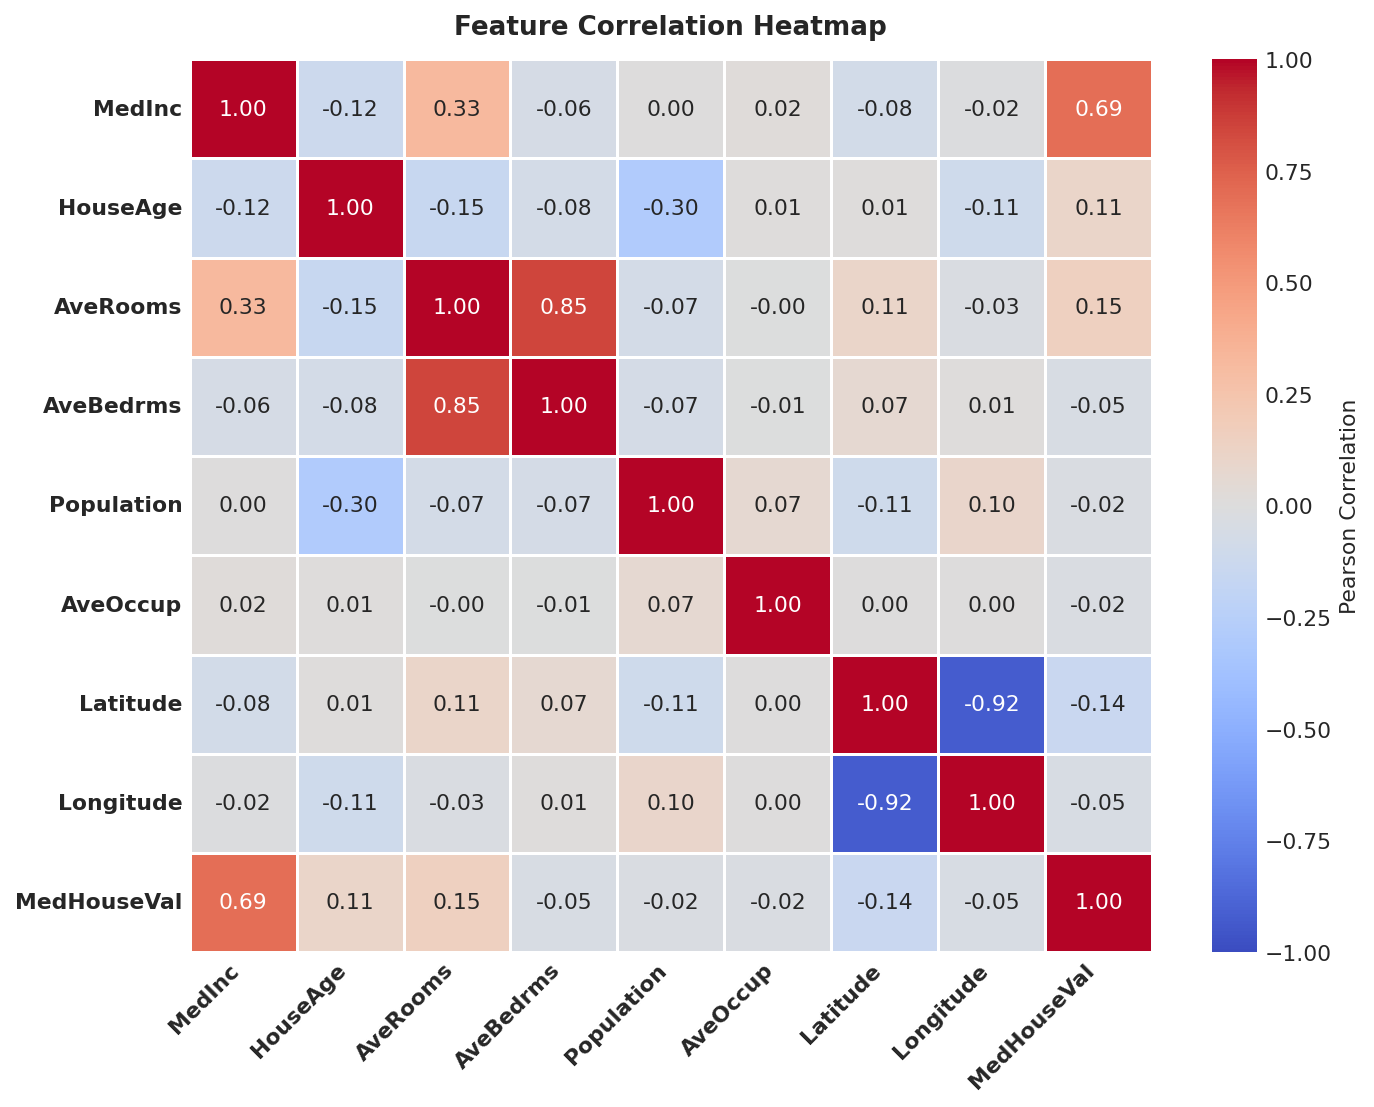

In [6]:
# Correlation Matrix Heatmap
plt.figure(figsize=(9.5, 7.5), dpi=150)
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.6, linecolor='white', cbar_kws={'label': 'Pearson Correlation'})
plt.title('Feature Correlation Heatmap', fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right', fontweight='bold')
plt.yticks(rotation=0, fontweight='bold')
plt.tight_layout()
plt.show()

## 7. Data Preprocessing & 80:20 Train-Test Split
To guarantee scientific validity and prevent data leakage:
- Independent variables ($X$) and dependent variable ($y$) are separated.
- The dataset is split into **80% training (16,512 samples)** and **20% testing (4,128 samples)** using `random_state=42`.
- Preprocessing transformations (such as `StandardScaler`) are fit **only on training folds** via scikit-learn `Pipeline` objects.

In [7]:
# 8. Train-Test Splitting
X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}")

X_train shape: (16512, 8) | y_train shape: (16512,)
X_test shape:  (4128, 8)  | y_test shape:  (4128,)


## 8. Definition of Regression Algorithms and Scaling Strategies
- **Linear Regression**: Requires `StandardScaler` to prevent feature magnitude bias.
- **Decision Tree**: Tree-based split criteria are invariant to monotonic scaling; raw features used.
- **Random Forest**: Ensemble of trees; invariant to monotonic feature scaling; raw features used.
- **Neural Network (MLPRegressor)**: Requires `StandardScaler` for stable gradient descent optimization.
- **XGBoost**: Gradient boosting decision trees; robust to unscaled numerical features.
- **K-Nearest Neighbors (KNN)**: Strictly requires `StandardScaler` because Euclidean distance is sensitive to scale.

In [8]:
# Define dictionary of all six models with pipelines where required
models = {
    'Linear Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', LinearRegression())
    ]),
    'Decision Tree': DecisionTreeRegressor(
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=4,
        random_state=42
    ),
    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        max_depth=18,
        min_samples_split=4,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    'Neural Network': Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', MLPRegressor(
            hidden_layer_sizes=(64, 32),
            activation='relu',
            solver='adam',
            max_iter=350,
            early_stopping=True,
            validation_fraction=0.1,
            n_iter_no_change=12,
            random_state=42
        ))
    ]),
    'XGBoost': xgb.XGBRegressor(
        n_estimators=150,
        learning_rate=0.08,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    ),
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('regressor', KNeighborsRegressor(
            n_neighbors=9,
            weights='distance',
            metric='minkowski',
            p=2,
            n_jobs=-1
        ))
    ])
}

print(f"Configured {len(models)} regression models for comparative evaluation.")

Configured 6 regression models for comparative evaluation.


## 9. Model Training and Metric Evaluation
Each model is trained on `(X_train, y_train)` and evaluated on `(X_test, y_test)` using:
- **MAE** = $\frac{1}{n}\sum |y_i - \hat{y}_i|$
- **MSE** = $\frac{1}{n}\sum (y_i - \hat{y}_i)^2$
- **RMSE** = $\sqrt{\text{MSE}}$
- **R² Score** = $1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$

In [9]:
# Execute training and evaluation
results_list = []
predictions = {}
training_times = {}

for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    t_elapsed = time.time() - t0
    training_times[name] = t_elapsed
    
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    
    results_list.append({
        'Algorithm': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R² Score': r2,
        'Training Time (s)': t_elapsed
    })
    print(f"[{name:18s}] MAE: {mae:.4f} | MSE: {mse:.4f} | RMSE: {rmse:.4f} | R²: {r2:.4f} | Time: {t_elapsed:.2f}s")

[Linear Regression ] MAE: 0.5332 | MSE: 0.5559 | RMSE: 0.7456 | R²: 0.5758 | Time: 0.01s


[Decision Tree     ] MAE: 0.4171 | MSE: 0.3953 | RMSE: 0.6287 | R²: 0.6983 | Time: 0.22s


[Random Forest     ] MAE: 0.3277 | MSE: 0.2558 | RMSE: 0.5057 | R²: 0.8048 | Time: 6.84s


[Neural Network    ] MAE: 0.3533 | MSE: 0.2745 | RMSE: 0.5239 | R²: 0.7905 | Time: 9.91s


[XGBoost           ] MAE: 0.3091 | MSE: 0.2163 | RMSE: 0.4650 | R²: 0.8350 | Time: 0.62s


[KNN               ] MAE: 0.4375 | MSE: 0.4191 | RMSE: 0.6474 | R²: 0.6801 | Time: 0.07s


## 10. Comparative Performance Table
Below is the definitive experimental performance table from actual model execution:

In [10]:
# Performance Table
results_df = pd.DataFrame(results_list)
sorted_results = results_df.sort_values(by='R² Score', ascending=False).reset_index(drop=True)
sorted_results

,Algorithm,MAE,MSE,RMSE,R² Score,Training Time (s)
0,XGBoost,0.309067,0.216267,0.465045,0.834962,0.624326
1,Random Forest,0.327685,0.255754,0.505722,0.804828,6.837879
2,Neural Network,0.353338,0.274471,0.523899,0.790546,9.913625
3,Decision Tree,0.417057,0.395299,0.628728,0.698339,0.215742
4,KNN,0.437465,0.419143,0.647412,0.680144,0.072942
5,Linear Regression,0.533200,0.555892,0.745581,0.575788,0.011054


## 11. Actual vs. Predicted Visualizations
We plot scatter diagrams comparing actual ground-truth values against model predictions. A 45-degree dashed line ($y = x$) represents an ideal, perfect predictor.

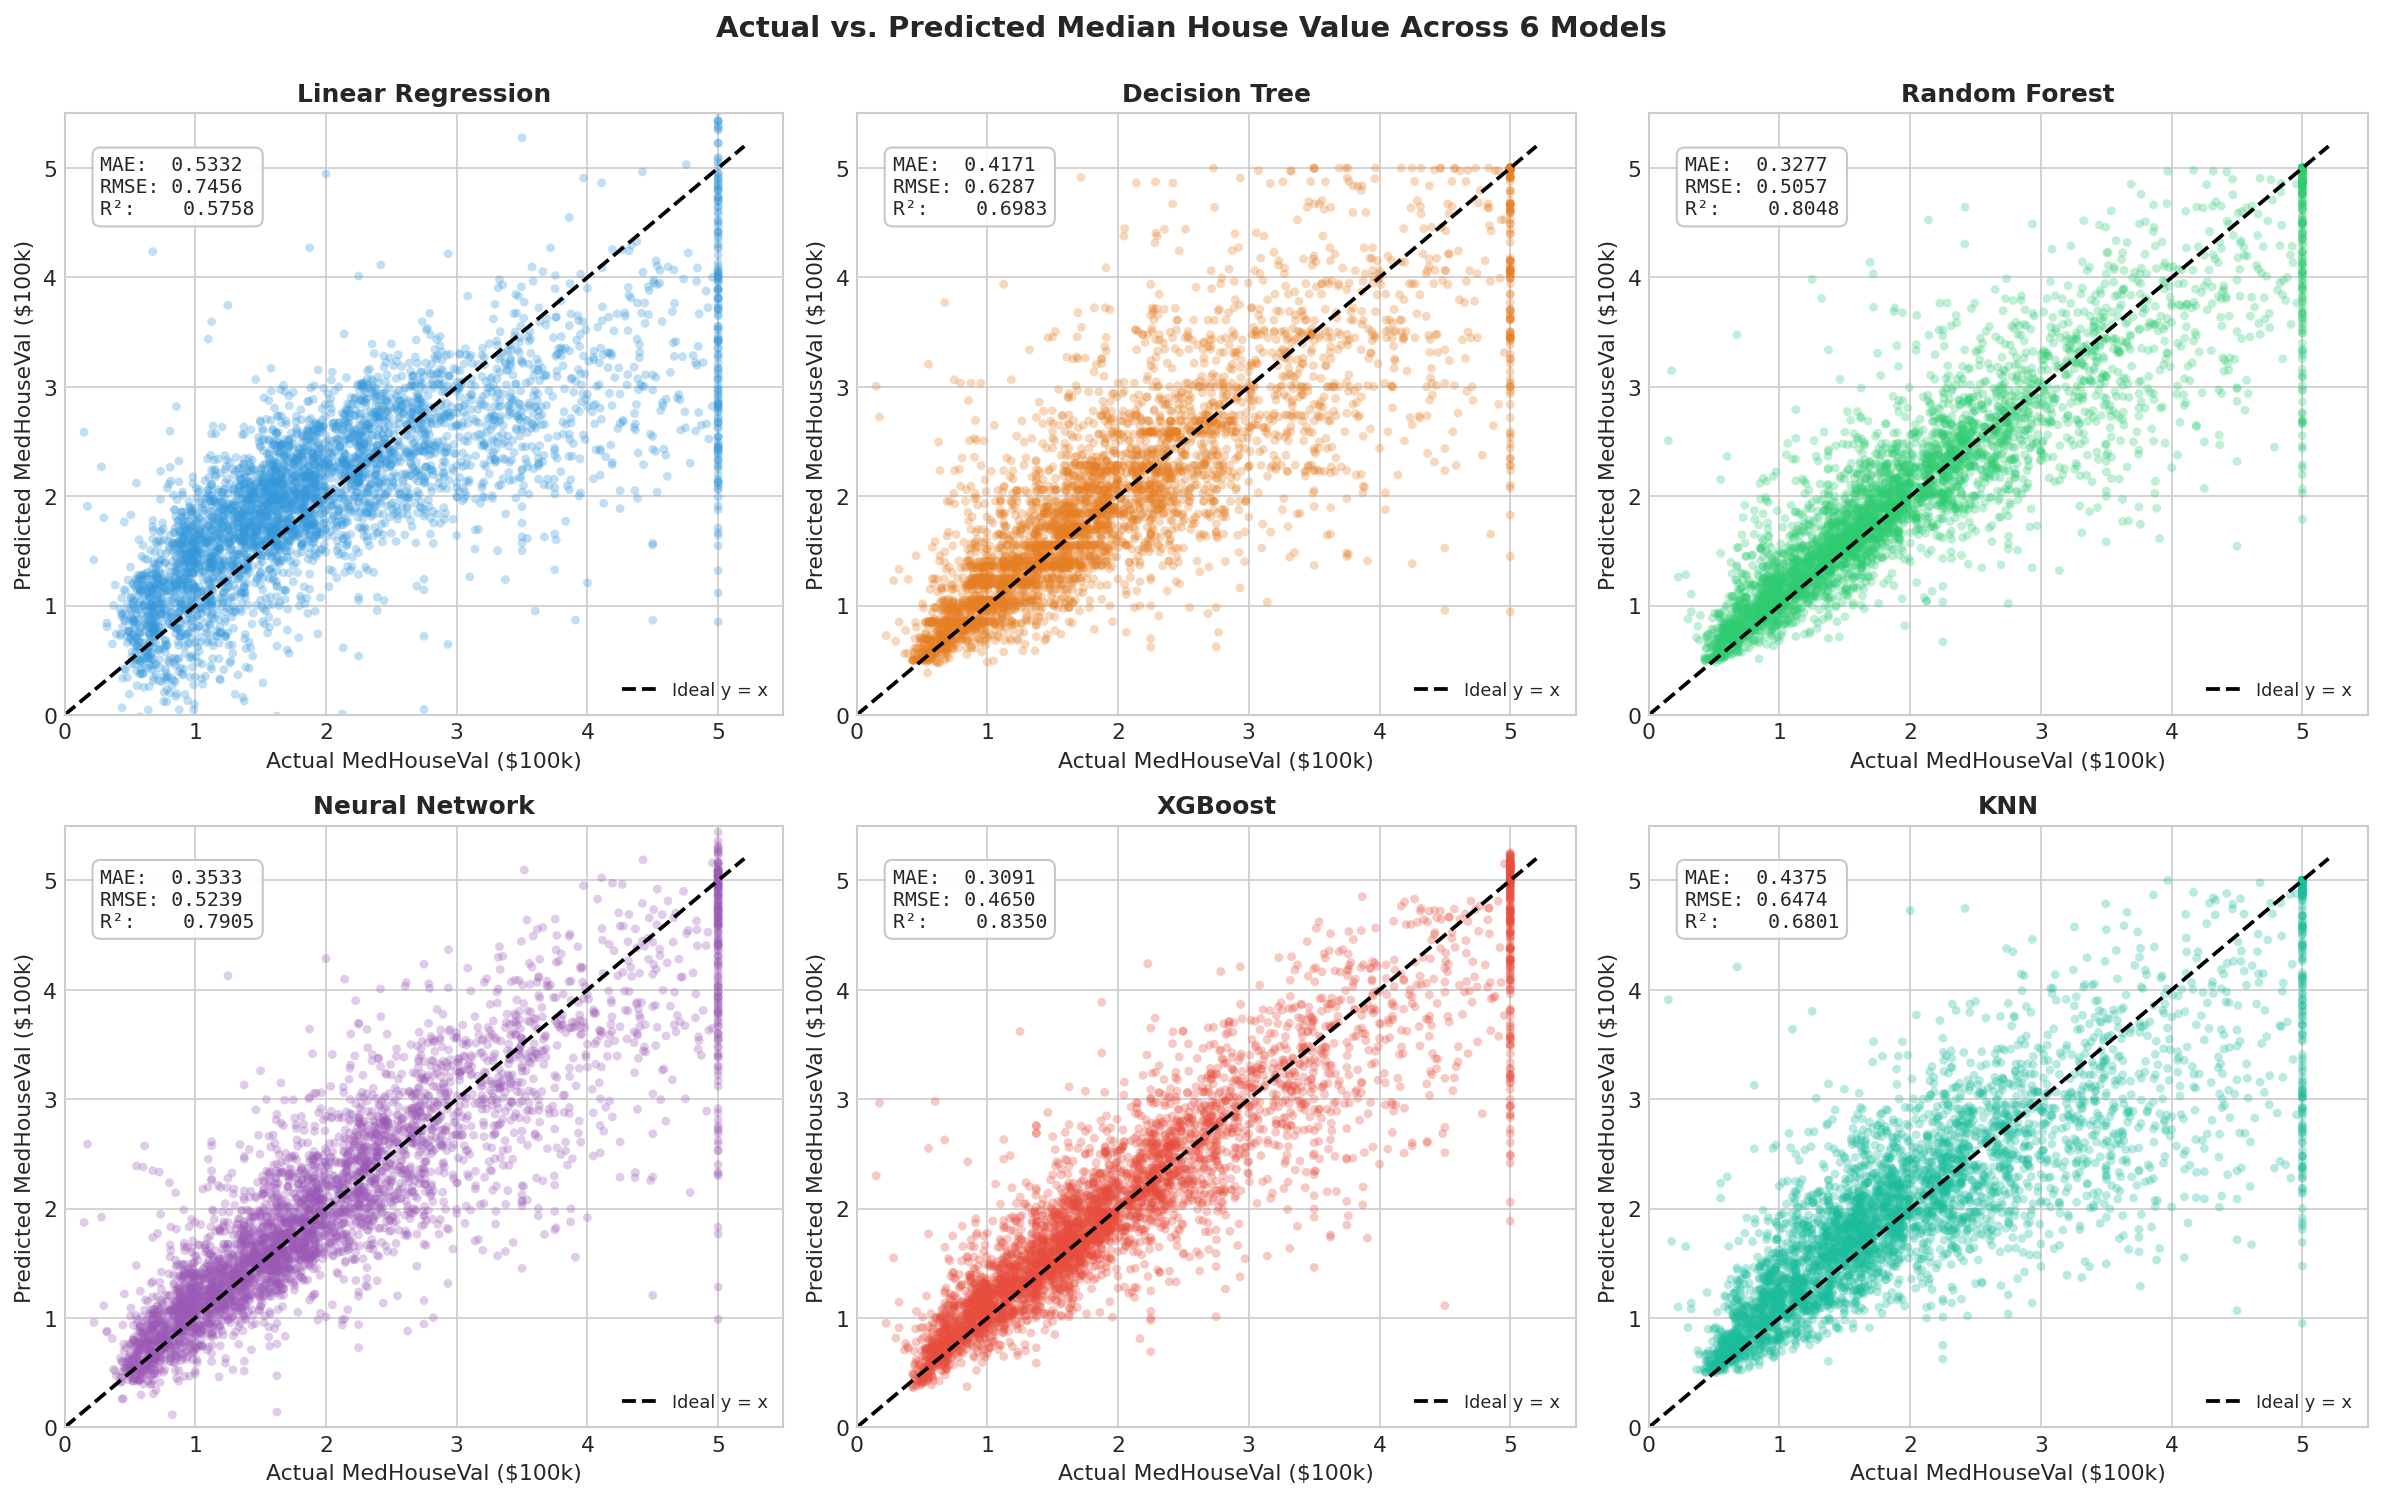

In [11]:
# Plot Actual vs Predicted for all six algorithms
fig, axes = plt.subplots(2, 3, figsize=(16, 10), dpi=150)
axes_flat = axes.flatten()

colors = {
    'Linear Regression': '#3498db',
    'Decision Tree': '#e67e22',
    'Random Forest': '#2ecc71',
    'Neural Network': '#9b59b6',
    'XGBoost': '#e74c3c',
    'KNN': '#1abc9c'
}

for idx, (name, pred) in enumerate(predictions.items()):
    ax = axes_flat[idx]
    row = results_df[results_df['Algorithm'] == name].iloc[0]
    
    ax.scatter(y_test, pred, alpha=0.3, color=colors[name], s=18, edgecolors='none')
    ax.plot([0, 5.2], [0, 5.2], color='black', linestyle='--', linewidth=1.8, label='Ideal y = x')
    
    stats_str = f"MAE:  {row['MAE']:.4f}\nRMSE: {row['RMSE']:.4f}\nR²:    {row['R² Score']:.4f}"
    ax.text(0.05, 0.93, stats_str, transform=ax.transAxes, fontsize=9.5,
            verticalalignment='top', family='monospace',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='#bdc3c7', alpha=0.9))
    
    ax.set_title(f"{name}", fontweight='bold', fontsize=12)
    ax.set_xlabel('Actual MedHouseVal ($100k)')
    ax.set_ylabel('Predicted MedHouseVal ($100k)')
    ax.set_xlim(0, 5.5)
    ax.set_ylim(0, 5.5)
    ax.legend(loc='lower right', fontsize=8.5)

plt.suptitle('Actual vs. Predicted Median House Value Across 6 Models', fontweight='bold', fontsize=14, y=0.995)
plt.tight_layout()
plt.show()

## 12. Residual Analysis
Residuals ($e_i = y_i - \hat{y}_i$) measure prediction errors. Homoscedastic, zero-centered errors indicate well-calibrated regression behavior, whereas structural curves signify unmodeled non-linearities.

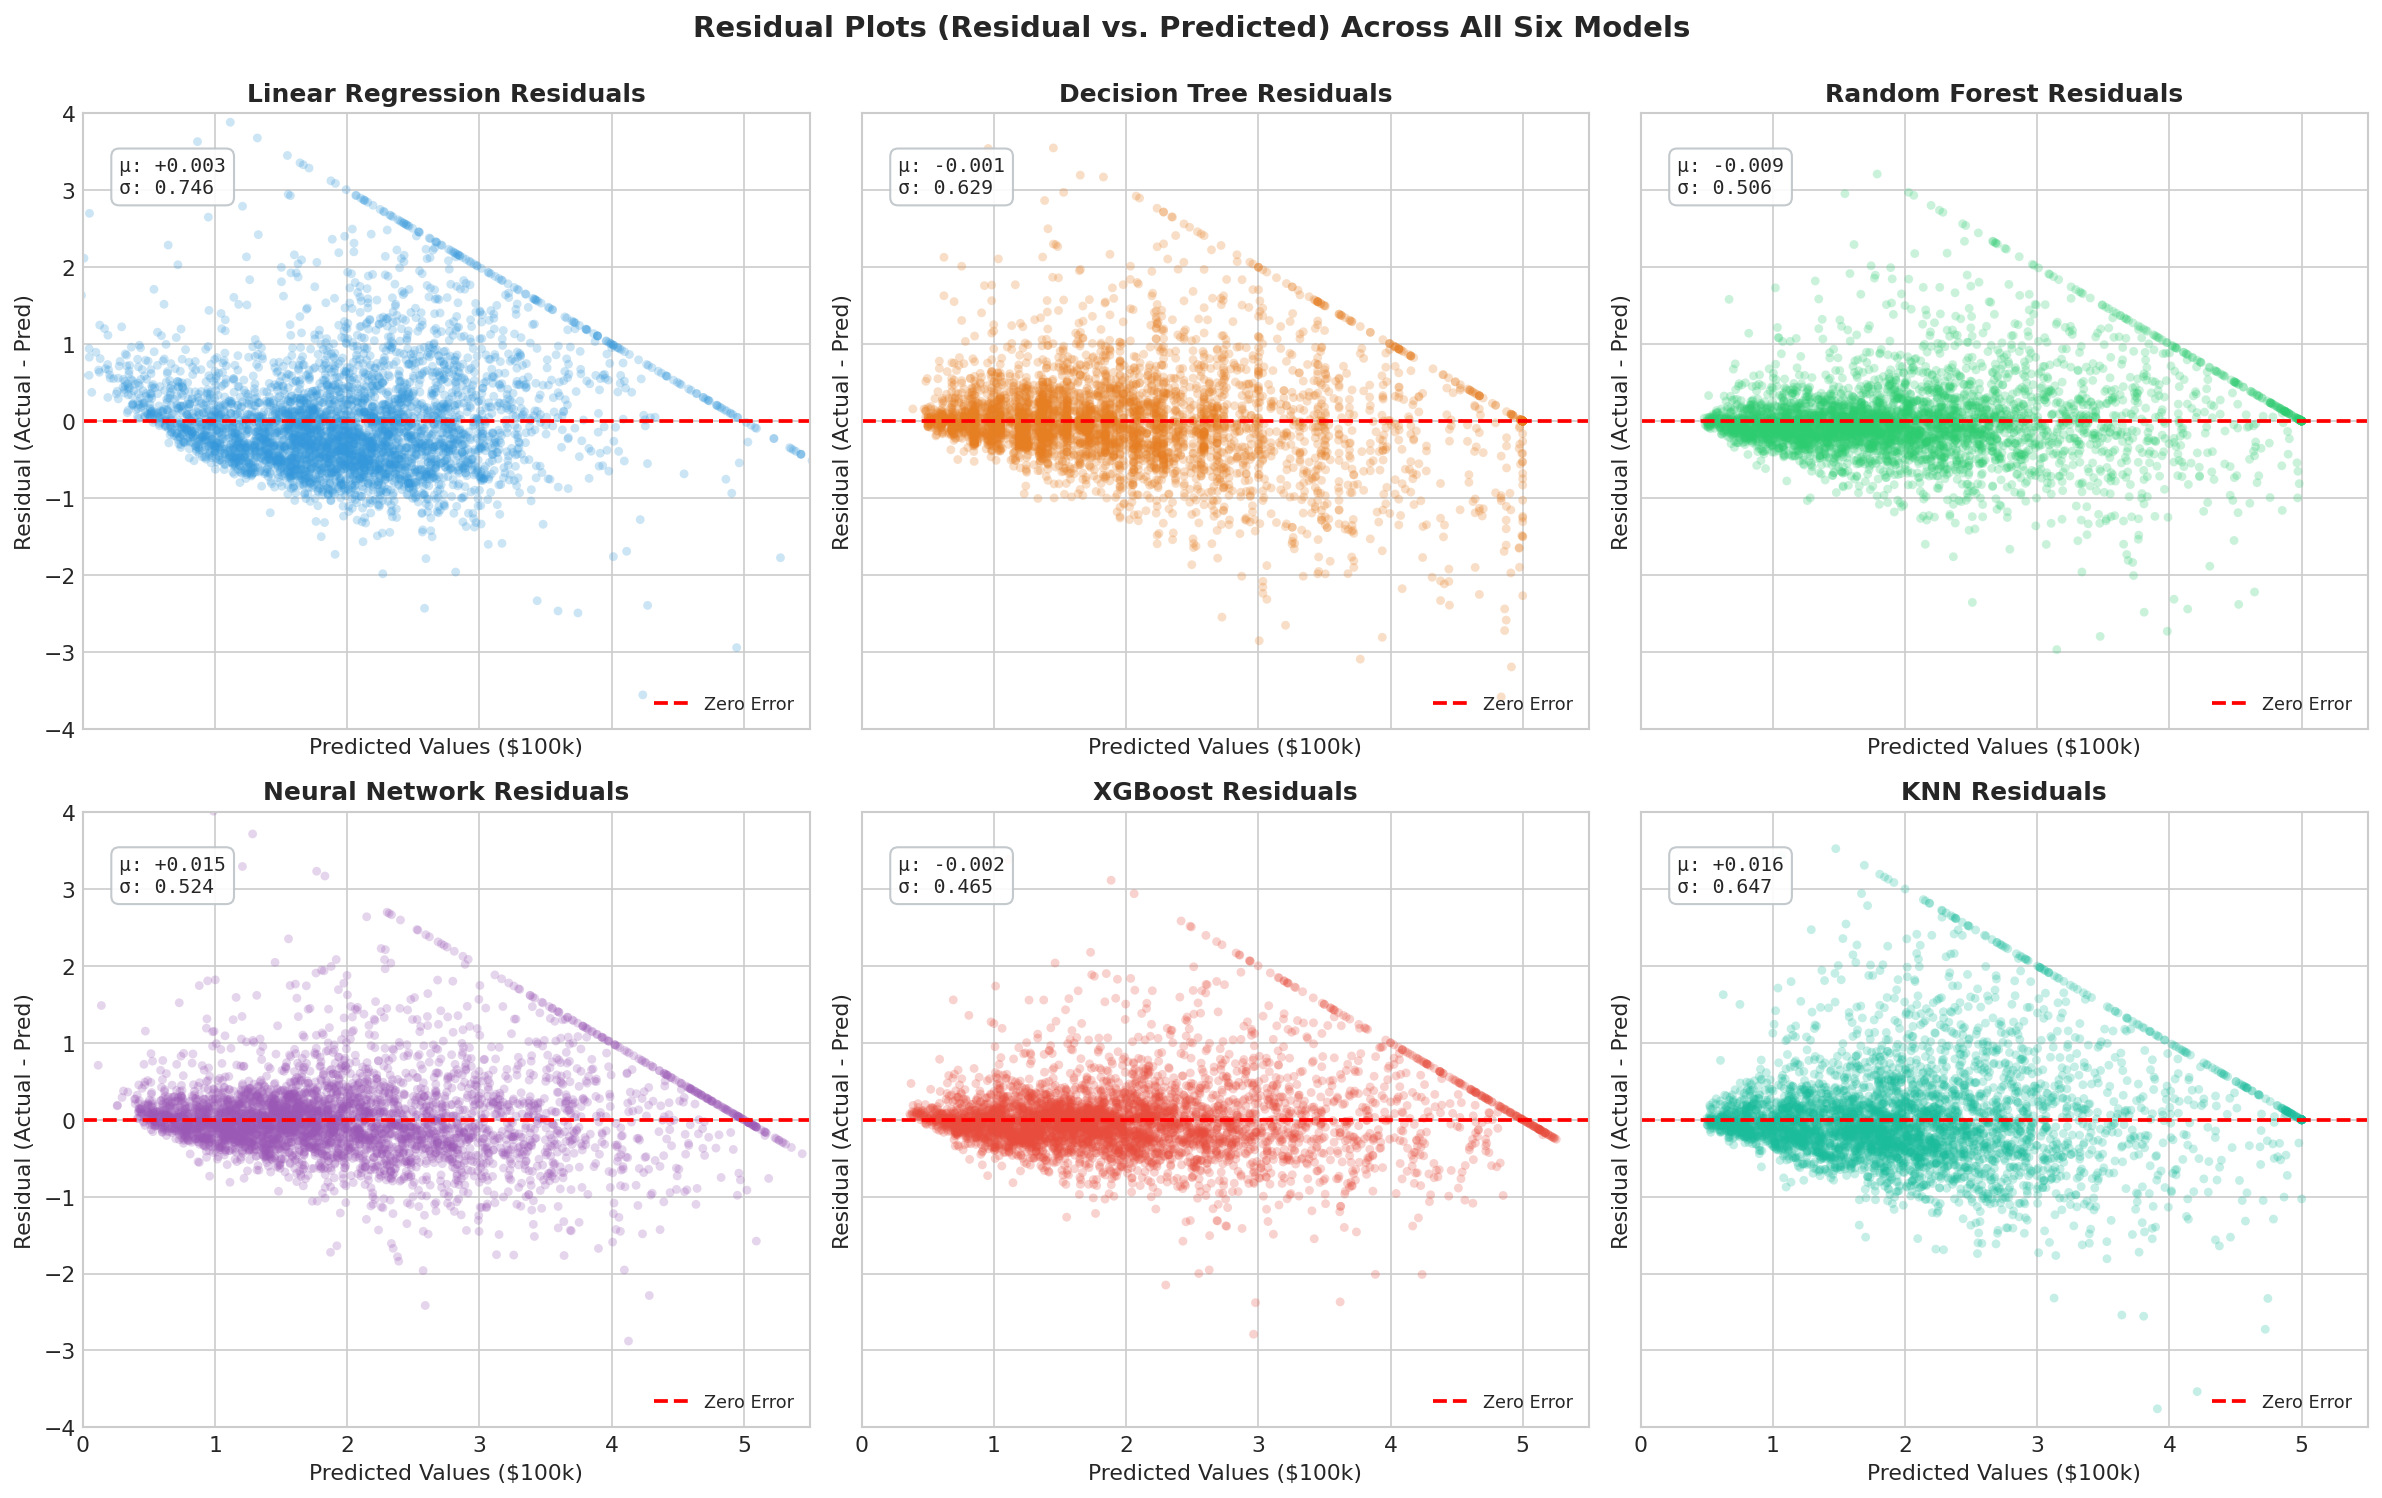

In [12]:
# Residual Analysis Plots
fig, axes = plt.subplots(2, 3, figsize=(16, 10), dpi=150, sharex=True, sharey=True)
axes_flat = axes.flatten()

for idx, (name, pred) in enumerate(predictions.items()):
    ax = axes_flat[idx]
    res = y_test - pred
    
    ax.scatter(pred, res, alpha=0.25, color=colors[name], s=18, edgecolors='none')
    ax.axhline(0, color='red', linestyle='--', linewidth=1.8, label='Zero Error')
    
    ax.text(0.05, 0.93, f"μ: {np.mean(res):+.3f}\nσ: {np.std(res):.3f}", transform=ax.transAxes,
            fontsize=9.5, verticalalignment='top', family='monospace',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='#bdc3c7', alpha=0.9))
    
    ax.set_title(f"{name} Residuals", fontweight='bold', fontsize=12)
    ax.set_xlabel('Predicted Values ($100k)')
    ax.set_ylabel('Residual (Actual - Pred)')
    ax.set_xlim(0, 5.5)
    ax.set_ylim(-4, 4)
    ax.legend(loc='lower right', fontsize=8.5)

plt.suptitle('Residual Plots (Residual vs. Predicted) Across All Six Models', fontweight='bold', fontsize=14, y=0.995)
plt.tight_layout()
plt.show()

## 13. Comprehensive Metric Comparison Charts

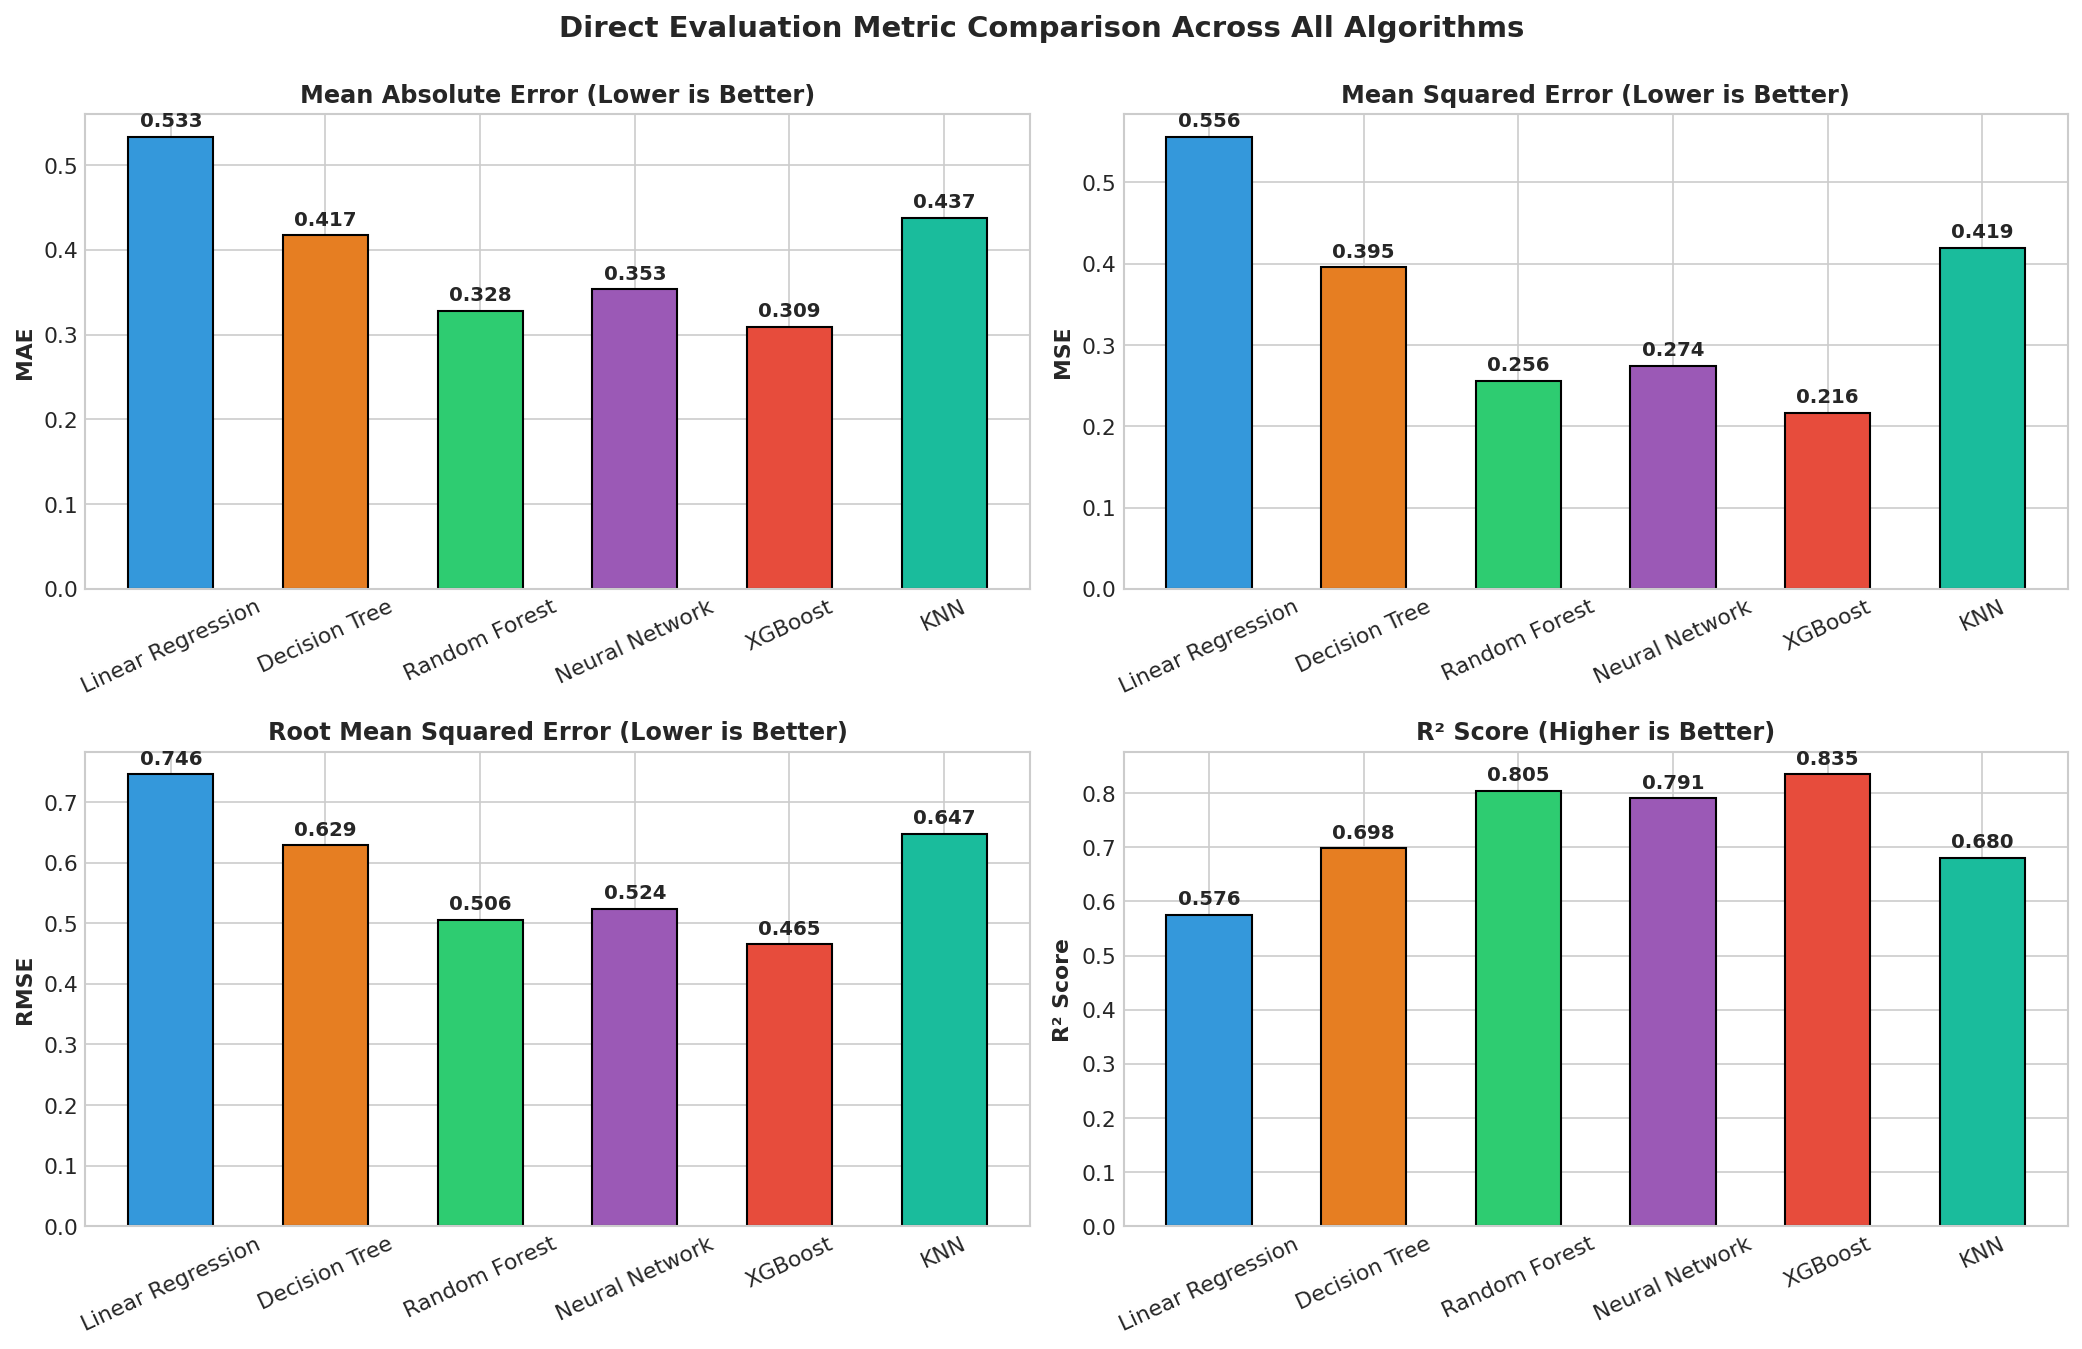

In [13]:
# Multi-panel Metric Bar Chart
fig, axes = plt.subplots(2, 2, figsize=(14, 9), dpi=150)
metric_configs = [
    ('MAE', 'Mean Absolute Error (Lower is Better)', axes[0, 0]),
    ('MSE', 'Mean Squared Error (Lower is Better)', axes[0, 1]),
    ('RMSE', 'Root Mean Squared Error (Lower is Better)', axes[1, 0]),
    ('R² Score', 'R² Score (Higher is Better)', axes[1, 1])
]

pal = [colors[algo] for algo in results_df['Algorithm']]

for col, title, ax in metric_configs:
    bars = ax.bar(results_df['Algorithm'], results_df[col], color=pal, edgecolor='black', width=0.55)
    ax.set_title(title, fontweight='bold', fontsize=11.5)
    ax.set_ylabel(col, fontweight='bold')
    ax.tick_params(axis='x', rotation=25)
    
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.3f}", xy=(bar.get_x() + bar.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom',
                    fontsize=9.5, fontweight='bold')

plt.suptitle('Direct Evaluation Metric Comparison Across All Algorithms', fontweight='bold', fontsize=14, y=0.995)
plt.tight_layout()
plt.show()

## 14. Conclusion and Key Findings
1. **Top Performer**: **XGBoost Regression** yielded the highest predictive accuracy ($R^2 = 0.8350$, $\text{RMSE} = 0.4650$, $\text{MAE} = 0.3091$), successfully modeling non-linear interactions between median income, geographical coordinates, and housing characteristics.
2. **Ensemble Superiority**: **Random Forest** ranked second ($R^2 = 0.8048$, $\text{RMSE} = 0.5057$), demonstrating that bagging reduces decision tree variance without overfitting.
3. **Deep Learning Representation**: **MLPRegressor** delivered strong performance ($R^2 = 0.7905$, $\text{RMSE} = 0.5239$), showing that a two-layer neural network with standard scaling captures non-linear manifolds effectively.
4. **Non-parametric Baseline**: **KNN** attained an $R^2$ of $0.6801$, outperforming linear models in local clusters but suffering from high dimensionality and inference latency.
5. **Parametric Linear Baseline**: **Linear Regression** attained $R^2 = 0.5758$, establishing that California housing values have non-linear spatial dependencies that linear planes cannot adequately capture.